# Etapa 3: protocolo de avaliação e pontos de referência

Entrada: `data/processed/renda.csv`, gerado pela etapa 1.

Antes da SVM, esta etapa fixa a régua: o protocolo de avaliação que todos os modelos seguem e o desempenho de modelos simples, contra os quais a SVM será comparada.

**Protocolo** (código em `src/avaliacao.py`, o mesmo da atividade 3):

- **Divisão estratificada 80/20**: 24.111 pessoas de treino e 6.028 de teste, com 24,9% de >50K nos dois lados.
- **10 seeds** (0 a 9): cada seed sorteia outra divisão; as tabelas trazem média ± desvio.
- **Validação cruzada estratificada de 5 partes dentro do treino** para escolher hiperparâmetros. O teste só é usado uma vez, no fim.
- **Pré-processamento dentro do pipeline**: one-hot nos 5 atributos de texto e padronização nos 5 numéricos, ajustados só com o treino de cada seed (e, na busca em grade, só com as partes de treino de cada rodada da validação cruzada).
- **Métricas**: acurácia, F1 macro (média do F1 das duas classes), F1 da classe >50K, AUC e matriz de confusão (falsos positivos e falsos negativos). Com 3 pessoas `<=50K` para cada `>50K`, a acurácia sozinha engana: um modelo que nunca encontra ninguém de renda alta acerta 75,1%.
- **Tempo**: um núcleo só para todos os modelos, uma rodada de aquecimento descartada, tempo de treino do modelo final separado do tempo da busca em grade, e mediana das 10 seeds.

Raça e sexo não entram nos modelos (`config.SENSIVEIS`).

Máquina: AMD Ryzen 5 9600X (6 núcleos, 12 threads), 31 GB de RAM, Windows 11, Python 3.14 e scikit-learn 1.9.1, a mesma da atividade 3.

## 0. Configuração

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from src import avaliacao, config

X, y = avaliacao.carregar()
print(X.shape, "| >50K:", round(y.mean(), 3))

(30139, 10) | >50K: 0.249


## 1. A divisão estratificada e o pré-processamento

In [2]:
X_tr, X_te, y_tr, y_te = avaliacao.dividir(X, y, seed=0)
display(pd.DataFrame({
    "pessoas": [len(y), len(y_tr), len(y_te)],
    "% >50K": [round(100 * s.mean(), 1) for s in (y, y_tr, y_te)],
}, index=["base inteira", "treino", "teste"]))

prep = avaliacao.preprocessador().fit(X_tr)
nomes = prep.get_feature_names_out()
print("colunas depois do pré-processamento:", len(nomes))
print(pd.Series([n.split("__")[1].rsplit("_", 1)[0] if n.startswith("categoricos") else n.split("__")[1]
                 for n in nomes]).value_counts().to_string())

,pessoas,% >50K
base inteira,30139,24.9
treino,24111,24.9
teste,6028,24.9


colunas depois do pré-processamento: 80
native.country    41
occupation        14
workclass          7
marital.status     7
relationship       6
age                1
education.num      1
capital.gain       1
capital.loss       1
hours.per.week     1


Os 5 atributos numéricos continuam como 5 colunas, padronizadas. Os 5 de texto viram 75 colunas de one-hot, uma por categoria: 41 países, 14 ocupações, 7 classes de trabalho, 7 estados civis e 6 relacionamentos. São 80 colunas no total, quase todas 0/1. O país sozinho responde por metade delas, embora 91% das pessoas tenham nascido nos EUA.

## 2. Os pontos de referência

- **Classe majoritária**: responde sempre `<=50K`. É o piso.
- **Regra de um corte**: uma árvore de profundidade 1, que aprende só com o treino uma única pergunta.
- **Regressão logística**: a fronteira reta mais simples, com os atributos padronizados. É o contraponto direto da SVM linear: as duas traçam um hiperplano, mas escolhem a posição dele por critérios diferentes.
- **Árvore de decisão**: com busca em grade (critério, profundidade máxima e mínimo de pessoas por folha, 30 combinações), como nas atividades 1 e 3.
- **Random Forest**: 300 árvores, configuração padrão, como nas atividades 2 e 3.

Todos recebem o mesmo pré-processamento, dentro de um `Pipeline`. A árvore e a Random Forest não precisam da padronização (comparam valores de um atributo por vez), mas ela não muda as perguntas que fazem.

In [3]:
GRADE_ARVORE = {
    "modelo__criterion": ["gini", "entropy"],
    "modelo__max_depth": [3, 5, 8, 12, None],
    "modelo__min_samples_leaf": [1, 5, 20],
}


def com_prep(modelo):
    return Pipeline([("prep", avaliacao.preprocessador()), ("modelo", modelo)])


def referencias(seed):
    return {
        "classe majoritária": com_prep(DummyClassifier(strategy="most_frequent")),
        "regra de um corte": com_prep(DecisionTreeClassifier(max_depth=1, random_state=seed)),
        "regressão logística": com_prep(LogisticRegression(max_iter=1000)),
        "árvore de decisão": GridSearchCV(com_prep(DecisionTreeClassifier(random_state=seed)), GRADE_ARVORE,
                                          cv=avaliacao.validacao_cruzada(seed), n_jobs=1),
        "random forest": com_prep(RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=1)),
    }

## 3. Resultados nas 10 seeds

In [4]:
resultados = avaliacao.rodar_seeds(referencias, X, y)

config.RESULTS_DIR.mkdir(exist_ok=True)
resultados.to_csv(config.RESULTS_DIR / "referencias.csv", index=False)

avaliacao.resumir(resultados)

,acurácia,F1 macro,F1 >50K,AUC,falsos positivos (média),falsos negativos (média),tempo de treino (s) · mediana,tempo da busca (s) · mediana,tempo de previsão (ms) · mediana
modelo,,,,,,,,,
classe majoritária,75.1 ± 0.0,42.9 ± 0.0,0.0 ± 0.0,50.0 ± 0.0,0.0,1501.0,0.0148,NaN,4.3379
regra de um corte,75.1 ± 0.0,42.9 ± 0.0,0.0 ± 0.0,75.6 ± 0.6,0.0,1501.0,0.0216,NaN,4.8009
regressão logística,84.8 ± 0.3,78.3 ± 0.4,66.5 ± 0.6,90.2 ± 0.4,324.9,591.5,0.0618,NaN,4.5432
árvore de decisão,85.2 ± 0.4,78.4 ± 0.8,66.4 ± 1.6,90.0 ± 0.4,277.4,616.7,0.0551,7.2871,5.0971
random forest,84.3 ± 0.4,78.1 ± 0.6,66.5 ± 0.8,89.1 ± 0.5,390.7,558.7,2.8409,NaN,179.9893


**Leitura da tabela** (média ± desvio de 10 seeds; tempos em mediana):

- **Classe majoritária e regra de um corte** empatam em tudo, menos na AUC: 75,1% de acurácia, F1 da classe >50K igual a zero e 1.501 falsos negativos, ou seja, nenhuma pessoa de renda alta encontrada. A seção 4 explica por quê.
- **Regressão logística**: 84,8 ± 0,3% de acurácia, 9,7 pontos acima do piso, com AUC de 90,2%. Uma fronteira reta já vai longe nesta base.
- **Árvore de decisão ajustada**: 85,2 ± 0,4%, a melhor acurácia, e o menor número de falsos positivos (277).
- **Random Forest**: 84,3 ± 0,4%, abaixo da árvore e da regressão logística (seção 6).

Nos três modelos que aprendem, o F1 da classe >50K fica perto de 66%, bem abaixo do F1 da classe `<=50K` (cerca de 90%): a média dos dois dá o F1 macro de 78%. E os falsos negativos são cerca de o dobro dos falsos positivos: de 1.501 pessoas que ganham mais de 50 mil no teste, os modelos deixam passar cerca de 600 (40%), enquanto classificam por engano cerca de 300 das 4.527 que ganham menos (7%). É o efeito do desbalanceamento: com 3 pessoas `<=50K` para cada `>50K`, na dúvida o modelo responde `<=50K`.

## 4. O que a regra de um corte aprendeu

In [5]:
regras = []
for seed in config.SEEDS:
    X_tr, X_te, y_tr, y_te = avaliacao.dividir(X, y, seed)
    regra = com_prep(DecisionTreeClassifier(max_depth=1, random_state=seed)).fit(X_tr, y_tr)
    arvore = regra.named_steps["modelo"]
    taxa_folhas = arvore.tree_.value[1:, 0, 1]  # fração de >50K em cada lado da pergunta
    regras.append({
        "seed": seed,
        "pergunta": regra.named_steps["prep"].get_feature_names_out()[arvore.tree_.feature[0]],
        "% >50K em cada lado": " / ".join(f"{100 * v:.1f}" for v in taxa_folhas),
        "% de previsões >50K no teste": round(100 * regra.predict(X_te).mean(), 1),
    })
pd.DataFrame(regras).set_index("seed")

,pergunta,% >50K em cada lado,% de previsões >50K no teste
seed,,,
0,categoricos__marital.status_Married-civ-spouse,6.8 / 45.7,0.0
1,categoricos__marital.status_Married-civ-spouse,7.0 / 45.4,0.0
2,categoricos__marital.status_Married-civ-spouse,6.9 / 45.4,0.0
3,categoricos__marital.status_Married-civ-spouse,6.9 / 45.4,0.0
4,categoricos__marital.status_Married-civ-spouse,6.9 / 45.7,0.0
5,categoricos__marital.status_Married-civ-spouse,6.9 / 45.5,0.0
6,categoricos__marital.status_Married-civ-spouse,7.0 / 45.4,0.0
7,categoricos__marital.status_Married-civ-spouse,6.9 / 45.4,0.0
8,categoricos__marital.status_Married-civ-spouse,6.8 / 45.5,0.0


A árvore de profundidade 1 escolhe a mesma pergunta nas 10 seeds: **a pessoa é casada (*Married-civ-spouse*)?** É a melhor pergunta possível, mas nenhum dos dois lados tem maioria de >50K: entre os não casados, cerca de 7% ganham mais de 50 mil; entre os casados, cerca de 45%. Cada folha responde a classe mais comum do seu lado, e a resposta é `<=50K` nos dois. A regra pergunta, mas responde sempre a mesma coisa, e por isso é idêntica à classe majoritária em acurácia e F1.

A AUC conta outra história: 75,6% contra 50% do chute. A AUC não usa o corte em 50%, usa a ordem: a regra dá nota 0,45 aos casados e 0,07 aos demais, e quem ganha mais de 50 mil tende a estar no grupo de nota maior. A informação está lá; o que falha é o corte. É o mesmo contraste entre acurácia e AUC da atividade 3, aqui levado ao extremo.

Na base de empréstimos, a regra de um corte acertava 95,5%. Aqui ela não sai do piso: nenhum atributo sozinho separa as classes, como a análise exploratória já indicava.

## 5. Árvore escolhida pela busca

In [6]:
escolhas = resultados.loc[resultados["modelo"] == "árvore de decisão", "hiperparâmetros"]
escolhas.value_counts()

hiperparâmetros
{'modelo__criterion': 'gini', 'modelo__max_depth': 12, 'modelo__min_samples_leaf': 20}         2
{'modelo__criterion': 'gini', 'modelo__max_depth': 8, 'modelo__min_samples_leaf': 5}           2
{'modelo__criterion': 'entropy', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 20}    1
{'modelo__criterion': 'gini', 'modelo__max_depth': 8, 'modelo__min_samples_leaf': 1}           1
{'modelo__criterion': 'entropy', 'modelo__max_depth': 8, 'modelo__min_samples_leaf': 5}        1
{'modelo__criterion': 'gini', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 20}       1
{'modelo__criterion': 'entropy', 'modelo__max_depth': 12, 'modelo__min_samples_leaf': 20}      1
{'modelo__criterion': 'gini', 'modelo__max_depth': 8, 'modelo__min_samples_leaf': 20}          1
Name: count, dtype: int64

A busca escolhe 8 combinações diferentes em 10 seeds, quase todas com profundidade de 8 para cima e pelo menos 5 pessoas por folha. Muitas configurações dão praticamente o mesmo resultado na validação cruzada, e a escolha varia com o sorteio. O ponto comum é a árvore não ir até o fim: folhas com 5 a 20 pessoas no mínimo, ou profundidade limitada.

## 6. Comparações seed a seed

In [7]:
pares = resultados.pivot(index="seed", columns="modelo", values="acurácia")
comparacoes = {
    "regressão logística − classe majoritária": pares["regressão logística"] - pares["classe majoritária"],
    "árvore − regressão logística": pares["árvore de decisão"] - pares["regressão logística"],
    "random forest − árvore": pares["random forest"] - pares["árvore de decisão"],
    "random forest − regressão logística": pares["random forest"] - pares["regressão logística"],
}
pd.DataFrame({
    nome: {"diferença média (pontos)": round(100 * d.mean(), 2), "desvio (pontos)": round(100 * d.std(), 2),
           "seeds com diferença positiva": int((d > 0).sum())}
    for nome, d in comparacoes.items()
}).T

,diferença média (pontos),desvio (pontos),seeds com diferença positiva
regressão logística − classe majoritária,9.70,0.30,10.0
árvore − regressão logística,0.37,0.39,8.0
random forest − árvore,-0.92,0.46,0.0
random forest − regressão logística,-0.55,0.32,0.0


## 7. Acerto e tempo de treino

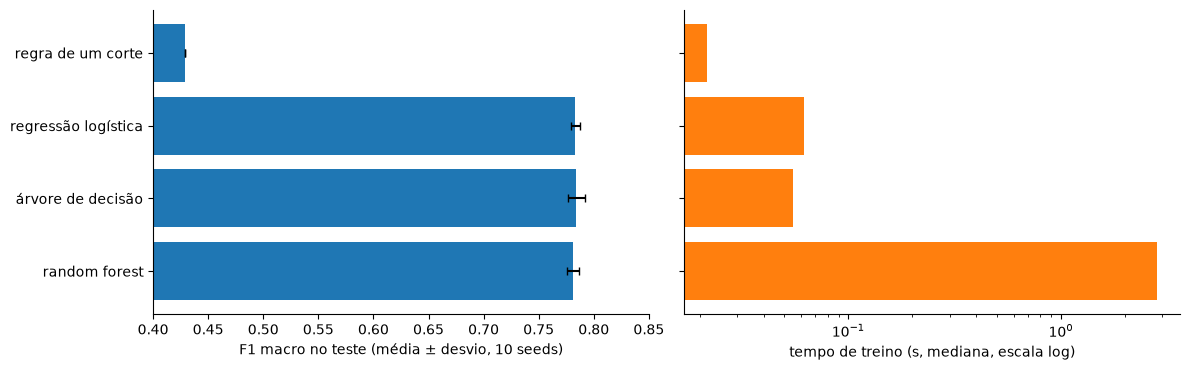

In [8]:
modelos = [m for m in resultados["modelo"].unique() if m != "classe majoritária"]
grupos = resultados.groupby("modelo")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
media, desvio = grupos["F1 macro"].mean()[modelos], grupos["F1 macro"].std()[modelos]
ax1.barh(modelos, media, xerr=desvio, color="tab:blue", capsize=3)
ax1.set_xlim(0.4, 0.85)
ax1.set_xlabel("F1 macro no teste (média ± desvio, 10 seeds)")
ax1.invert_yaxis()
ax1.spines[["top", "right"]].set_visible(False)

tempo = grupos["tempo de treino (s)"].median()[modelos]
ax2.barh(modelos, tempo, color="tab:orange")
ax2.set_xscale("log")
ax2.set_xlabel("tempo de treino (s, mediana, escala log)")
ax2.invert_yaxis()
ax2.set_yticklabels([])
ax2.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Resultado.** A régua para a SVM, em média de 10 seeds:

- **Piso**: responder sempre `<=50K` acerta 75,1%, com F1 macro de 42,9% e AUC de 50%. A regra de um corte não sai desse piso: pergunta se a pessoa é casada, mas responde `<=50K` nos dois casos.
- **Regressão logística**: 84,8% de acurácia, F1 macro de 78,3% e AUC de 90,2%. É a referência direta da SVM linear, as duas com fronteira reta.
- **Árvore de decisão ajustada**: 85,2%, a melhor acurácia, à frente da regressão logística em 8 das 10 seeds (+0,4 ponto).
- **Random Forest**: 84,3%, abaixo da árvore nas 10 seeds (−0,9 ponto) e da regressão logística também nas 10. Na configuração padrão, cada árvore da floresta cresce até separar todas as pessoas do treino (folhas com 1 pessoa). Nesta base, 8% das linhas estão em perfis que aparecem com as duas rendas: crescer até o fim é decorar esse ruído. A árvore ajustada, com folhas de 5 a 20 pessoas, não faz isso. Não ajustamos a floresta, por isso o resultado vale para a configuração padrão, a mesma das atividades 2 e 3.

Os três modelos ficam a menos de 1 ponto um do outro, e os três erram mais por falso negativo (cerca de 600) do que por falso positivo (cerca de 300). Esse é o desafio para a SVM: superar 85% de acurácia e 78% de F1 macro, e reduzir os falsos negativos sem trocar por falsos positivos demais.

**Tempo** (um núcleo, mediana de 10 seeds): a regressão logística e a árvore treinam em cerca de 60 ms; a busca em grade da árvore (150 treinos) leva cerca de 7 s por seed. A Random Forest leva cerca de 3 s para treinar e é a mais lenta para prever, cerca de 180 ms para as 6.028 pessoas do teste, mais de 30 vezes os outros modelos, porque cada pessoa passa pelas 300 árvores. Na medição exploratória, a SVM com kernel RBF levou cerca de 5 s para treinar no treino inteiro com C = 1.